# Guardião — Risco de sinistro grave com moto em São Paulo

**Disciplina:** Inteligência Artificial & Machine Learning — Global Solution 2026.2 (CitizenTech)
**Cidadão:** entregador de moto (motoboy) que trabalha por aplicativo em São Paulo.

## 1. Problema e pergunta de Machine Learning

O motoboy não sabe em quais regiões e horários o risco é maior. O Guardião mostra no app um
**score de risco por região e faixa horária**. Esse score sai deste notebook.

> **Pergunta de ML:** dado um sinistro de trânsito envolvendo moto na cidade de São Paulo, com este
> **local**, **dia da semana** e **horário**, qual a chance de ele ser **grave ou fatal**?

- **Tipo de problema:** classificação binária — `1` = grave ou fatal, `0` = leve.
- **Dados:** Infosiga SP (DETRAN-SP), dados abertos e **reais** (nada simulado).
- **Modelo:** XGBoost (justificativa na seção 6).
- **Métricas principais:** recall e F1 da classe grave e ROC-AUC. A acurácia **não** é usada como
  métrica principal porque a classe grave é minoria (~12%).
- **Saída para o resto do projeto:** `zonas_risco.csv`, consumido pela API (`GET /api/zonas-risco`).

**Variáveis usadas:** só o que se sabe *antes* de um acidente — onde (coordenada, tipo de via e de
logradouro) e quando (hora, dia da semana, mês). Ficam de fora o tipo de colisão e os veículos
envolvidos: eles só existem depois do acidente e o app, na hora de avisar o motoboy, não os conhece.

In [1]:
import json, re, time, urllib.request, zipfile, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import sklearn, xgboost
from sklearn.compose import ColumnTransformer
from sklearn.inspection import permutation_importance
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, average_precision_score,
                             balanced_accuracy_score, confusion_matrix, f1_score, precision_score,
                             recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import (GridSearchCV, StratifiedKFold, cross_val_predict,
                                     train_test_split)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from xgboost import XGBClassifier

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

SEED = 42
DADOS = Path("dados")
RAW = DADOS / "raw"
PROC = DADOS / "processados"
FIG = Path("figuras")
for p in (RAW, PROC, FIG):
    p.mkdir(parents=True, exist_ok=True)

# Paleta: azul = treino / classe leve, laranja = teste / classe grave (ordem fixa, validada p/ daltonismo)
AZUL, LARANJA, VERDE, CINZA = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#b5b4ad", "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.titleweight": "bold", "axes.titlesize": 12, "font.size": 10,
    "legend.frameon": False,
})
print("pandas", pd.__version__, "| scikit-learn", sklearn.__version__, "| xgboost", xgboost.__version__)

pandas 3.1.1 | scikit-learn 1.9.1 | xgboost 3.4.1


## 2. Dados reais e públicos

| Item | Valor |
|---|---|
| **Fonte** | Infosiga SP — Sistema de Informações Gerenciais de Sinistros de Trânsito, DETRAN-SP / Governo do Estado de SP |
| **Portal** | https://infosiga.detran.sp.gov.br/ → *Dados Abertos e Documentos* → *Download dos dados* |
| **Arquivo** | https://infosiga.detran.sp.gov.br/painel/download/file/dados_infosiga.zip |
| **Dicionário** | https://infosiga.detran.sp.gov.br/painel/download/file/Infosiga_dicionario_dados.zip (v1.8, 15/10/2026) |
| **Download** | 12/11/2026 (portal na versão 3.1, dados atualizados em 19/10/2026) |
| **Período usado** | 01/01/2019 até o último mês publicado de 2026 |

O ZIP traz três tabelas ligadas por `id_sinistro` (sinistros, pessoas, veículos), em CSV separado por `;`,
codificação Latin-1 e vírgula decimal. Usamos a tabela **sinistros**: ela já tem data, hora, coordenadas,
tipo de via, quantidade de motos envolvidas e a contagem de vítimas por gravidade.

**Por que começar em 2019:** até 2018 o Infosiga só registrava sinistros **fatais**. Usar esses anos
deixaria a classe grave artificialmente inflada.

A célula abaixo baixa o ZIP oficial se ele ainda não estiver em `dados/raw/` (141 MB, não versionado no Git).

In [2]:
URL_ZIP = "https://infosiga.detran.sp.gov.br/painel/download/file/dados_infosiga.zip"
ZIP = RAW / "dados_infosiga.zip"

if not ZIP.exists():
    print("Baixando", URL_ZIP)
    urllib.request.urlretrieve(URL_ZIP, ZIP)
with open(ZIP, "rb") as f:
    assert f.read(4) == b"PK\x03\x04", "O portal devolveu uma página HTML em vez do ZIP; baixe manualmente."

z = zipfile.ZipFile(ZIP)
arquivos = [i for i in z.infolist() if i.filename.startswith("sinistros_")]
for i in arquivos:
    print(f"{i.filename:28s} {i.file_size/1e6:7.1f} MB")

partes = []
for i in arquivos:
    df_i = pd.read_csv(z.open(i.filename), sep=";", encoding="latin-1", decimal=",", low_memory=False)
    partes.append(df_i)
bruto = pd.concat(partes, ignore_index=True)
print("\nSinistros no estado de SP (todos os anos):", f"{len(bruto):,}".replace(",", "."))
print("Colunas:", len(bruto.columns))
bruto.head(3)

sinistros_2015-2021.csv        142.0 MB
sinistros_2022-2024.csv        157.9 MB
sinistros_2025-2026.csv         80.9 MB



Sinistros no estado de SP (todos os anos): 1.450.961
Colunas: 50


,id_sinistro,tipo_registro,data_sinistro,ano_sinistro,mes_sinistro,dia_sinistro,hora_sinistro,ano_mes_sinistro,dia_da_semana,turno,logradouro,numero_logradouro,tipo_via,tipo_local,latitude,longitude,cod_ibge,municipio,regiao_administrativa,administracao,conservacao,circunscricao,tp_sinistro_primario,qtd_pedestre,qtd_bicicleta,qtd_motocicleta,qtd_automovel,qtd_onibus,qtd_caminhao,qtd_veic_outros,qtd_veic_nao_disponivel,qtd_gravidade_fatal,qtd_gravidade_grave,qtd_gravidade_leve,qtd_gravidade_ileso,qtd_gravidade_nao_disponivel,tp_sinistro_atrop_pedestre,tp_sinistro_atrop_vitima_fora_veic,tp_sinistro_colisao_frontal,tp_sinistro_colisao_traseira,tp_sinistro_colisao_lateral,tp_sinistro_colisao_transversal,tp_sinistro_colisao_outros,tp_sinistro_choque,tp_sinistro_atrop_animal,tp_sinistro_capotamento,tp_sinistro_engavetamento,tp_sinistro_tombamento,tp_sinistro_outros,tp_sinistro_nao_disponivel
0,2489730,SINISTRO FATAL,28/12/2014,2014,12,28,NaN,2014/12,Domingo,NAO DISPONIVEL,AVENIDA SAO PAULO,NaN,VIAS URBANAS,NAO DISPONIVEL,-24.013510,-46.417382,3541000,PRAIA GRANDE,BAIXADA SANTISTA,PREFEITURA,PREFEITURA,MUNICIPAL,NAO DISPONIVEL,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,S
1,2456933,SINISTRO FATAL,23/12/2014,2014,12,23,NaN,2014/12,Terça-feira,NAO DISPONIVEL,AVENIDA VINTE E TRES,1000.0,VIAS URBANAS,NAO DISPONIVEL,-20.558391,-48.571874,3505500,BARRETOS,BARRETOS,PREFEITURA,PREFEITURA,MUNICIPAL,NAO DISPONIVEL,NaN,NaN,NaN,2.0,NaN,NaN,1.0,NaN,1.0,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,S
2,2493691,SINISTRO FATAL,01/01/2015,2015,1,1,23:38,2015/01,Quinta-feira,NOITE,BR 116,431.0,VIAS URBANAS,PUBLICO,-24.411162,-47.753027,3542602,REGISTRO,REGISTRO,PREFEITURA,PREFEITURA,MUNICIPAL,OUTROS,NaN,NaN,NaN,2.0,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,S,NaN


### 2.1 Colunas conferidas

Antes de qualquer modelo, conferimos que existem as colunas exigidas pelo plano:
data e hora, latitude/longitude, tipo de veículo (aqui, a quantidade de motos) e gravidade.

In [3]:
exigidas = {
    "data e hora": ["data_sinistro", "hora_sinistro"],
    "localização": ["latitude", "longitude", "logradouro", "municipio"],
    "tipo de veículo": ["qtd_motocicleta"],
    "gravidade": ["qtd_gravidade_fatal", "qtd_gravidade_grave", "qtd_gravidade_leve",
                  "qtd_gravidade_ileso", "qtd_gravidade_nao_disponivel"],
    "contexto da via": ["tipo_via", "administracao"],
}
for grupo, cols in exigidas.items():
    faltando = [c for c in cols if c not in bruto.columns]
    print(f"{grupo:16s} {'OK' if not faltando else 'FALTANDO ' + str(faltando)}  {cols}")

data e hora      OK  ['data_sinistro', 'hora_sinistro']
localização      OK  ['latitude', 'longitude', 'logradouro', 'municipio']
tipo de veículo  OK  ['qtd_motocicleta']
gravidade        OK  ['qtd_gravidade_fatal', 'qtd_gravidade_grave', 'qtd_gravidade_leve', 'qtd_gravidade_ileso', 'qtd_gravidade_nao_disponivel']
contexto da via  OK  ['tipo_via', 'administracao']


## 3. Preparação e limpeza

Regras aplicadas, na ordem:

1. Município = **SAO PAULO** (capital).
2. Sinistro **com pelo menos uma moto** (`qtd_motocicleta ≥ 1`).
3. Data a partir de **01/01/2019**.
4. Remove `id_sinistro` duplicado.
5. Remove linhas **sem hora** ou **sem coordenada**, e coordenadas fora da caixa da cidade
   (há registros com 0,0 ou valores impossíveis como -87).
6. Remove sinistros **sem gravidade informada**: sem fatal, grave ou leve (só ileso / não disponível).
   Não dá para rotular esses casos sem inventar dado.

**Alvo:** `grave_fatal = 1` se o sinistro teve ao menos um morto ou ferido grave; `0` se o pior ferimento foi leve.

In [4]:
funil = [("Sinistros no estado de SP (2014–2026)", len(bruto))]

df = bruto[bruto["municipio"] == "SAO PAULO"].copy()
funil.append(("Município de São Paulo", len(df)))

df = df[df["qtd_motocicleta"].fillna(0) >= 1]
funil.append(("Com pelo menos uma moto", len(df)))

df["data"] = pd.to_datetime(df["data_sinistro"], format="%d/%m/%Y", errors="coerce")
df = df[df["data"] >= "2019-01-01"]
funil.append(("A partir de 2019", len(df)))

df = df.drop_duplicates("id_sinistro")
funil.append(("Sem id duplicado", len(df)))

hora = pd.to_datetime(df["hora_sinistro"], format="%H:%M", errors="coerce")
df["hora"] = hora.dt.hour
df = df[df["hora"].notna()]
funil.append(("Com hora válida", len(df)))

# caixa da cidade de São Paulo (WGS84)
caixa = df["latitude"].between(-24.01, -23.35) & df["longitude"].between(-46.83, -46.36)
df = df[caixa]
funil.append(("Com coordenada dentro da cidade", len(df)))

g = df[["qtd_gravidade_fatal", "qtd_gravidade_grave", "qtd_gravidade_leve"]].fillna(0)
tem_gravidade = (g.sum(axis=1) > 0)
df = df[tem_gravidade].copy()
g = g[tem_gravidade]
funil.append(("Com gravidade informada (fatal, grave ou leve)", len(df)))

df["grave_fatal"] = ((g["qtd_gravidade_fatal"] > 0) | (g["qtd_gravidade_grave"] > 0)).astype(int)

funil_df = pd.DataFrame(funil, columns=["etapa", "linhas"])
funil_df["removidas"] = (-funil_df["linhas"].diff()).fillna(0).astype(int)
print(f"Período final: {df['data'].min():%d/%m/%Y} a {df['data'].max():%d/%m/%Y}")
funil_df

Período final: 01/01/2019 a 30/09/2026


,etapa,linhas,removidas
0,Sinistros no estado de SP (2014–2026),1450961,0
1,Município de São Paulo,343241,1107720
2,Com pelo menos uma moto,135811,207430
3,A partir de 2019,134338,1473
4,Sem id duplicado,134338,0
5,Com hora válida,134243,95
6,Com coordenada dentro da cidade,129069,5174
7,"Com gravidade informada (fatal, grave ou leve)",124935,4134


In [5]:
contagem = df["grave_fatal"].value_counts().sort_index()
prop = df["grave_fatal"].mean()
print(f"Leves (0):        {contagem[0]:>7,}".replace(",", "."))
print(f"Graves/fatais (1):{contagem[1]:>7,}".replace(",", "."))
print(f"Proporção da classe grave: {prop:.1%}  ->  classe minoritária (desbalanceada)")
print("\nSinistros por ano (dado limpo):")
print(df.groupby(df['data'].dt.year)["grave_fatal"].agg(sinistros="size", taxa_grave="mean").round(3).to_string())

Leves (0):        111.008
Graves/fatais (1): 13.927
Proporção da classe grave: 11.1%  ->  classe minoritária (desbalanceada)

Sinistros por ano (dado limpo):
      sinistros  taxa_grave
data                       
2019      15769       0.112
2020      14465       0.119
2021      16262       0.107
2022      16769       0.109
2023      17433       0.102
2024      17558       0.108
2025      15033       0.122
2026      11646       0.118


## 4. Engenharia de variáveis

| Variável | Como foi criada | Tipo |
|---|---|---|
| `hora` | hora do sinistro (0–23) | numérica |
| `dia_semana` | 0 = segunda … 6 = domingo, calculado da data | numérica |
| `fim_de_semana` | 1 se sábado ou domingo | binária |
| `periodo` | madrugada (0–5h), manhã (6–11h), tarde (12–17h), noite (18–23h) — mesmo corte do Infosiga | categórica |
| `mes` | mês do ano (sazonalidade, chuva de verão) | numérica |
| `tipo_via` | vias urbanas ou estradas/rodovias | categórica |
| `tipo_logradouro` | primeira palavra do logradouro, padronizada: avenida, rua, rodovia, estrada, marginal, ponte/viaduto/túnel, outros | categórica |
| `administracao` | prefeitura, concessionária, DER… | categórica |
| `latitude`, `longitude` | coordenada do sinistro | numérica |
| `dist_centro_km` | distância em km até a Praça da Sé (centro × periferia) | numérica |

As categóricas são codificadas com **One-Hot Encoding** dentro de um `Pipeline`, para que a codificação
seja aprendida só com os dados de cada dobra de treino (sem vazamento).

In [6]:
df["dia_semana"] = df["data"].dt.day_of_week
df["fim_de_semana"] = (df["dia_semana"] >= 5).astype(int)
df["mes"] = df["data"].dt.month
df["periodo"] = pd.cut(df["hora"], bins=[-1, 5, 11, 17, 23],
                       labels=["MADRUGADA", "MANHA", "TARDE", "NOITE"]).astype(str)

def tipo_logradouro(nome):
    nome = str(nome).upper().strip()
    if "MARGINAL" in nome:
        return "MARGINAL"
    p = nome.split(" ")[0].rstrip(".") if nome else ""
    if p in ("AVENIDA", "AV"):
        return "AVENIDA"
    if p in ("RUA", "R"):
        return "RUA"
    if p in ("SP", "BR", "RODOVIA", "ROD") or nome.startswith("ACESSO"):
        return "RODOVIA"
    if p in ("ESTRADA", "EST"):
        return "ESTRADA"
    if p in ("PONTE", "VIADUTO", "TUNEL", "TÚNEL", "COMPLEXO"):
        return "PONTE_VIADUTO_TUNEL"
    return "OUTROS"

df["tipo_logradouro"] = df["logradouro"].map(tipo_logradouro)
df["administracao"] = df["administracao"].fillna("NAO DISPONIVEL").str.normalize("NFKD") \
    .str.encode("ascii", "ignore").str.decode("ascii")
df["tipo_via"] = df["tipo_via"].fillna("NAO DISPONIVEL")

SE = (-23.5503, -46.6339)  # Praça da Sé
lat_r, lon_r, se_lat, se_lon = map(np.radians, (df["latitude"], df["longitude"], SE[0], SE[1]))
a = np.sin((lat_r - se_lat) / 2) ** 2 + np.cos(lat_r) * np.cos(se_lat) * np.sin((lon_r - se_lon) / 2) ** 2
df["dist_centro_km"] = 6371 * 2 * np.arcsin(np.sqrt(a))

NUM = ["hora", "dia_semana", "fim_de_semana", "mes", "latitude", "longitude", "dist_centro_km"]
CAT = ["periodo", "tipo_via", "tipo_logradouro", "administracao"]
ALVO = "grave_fatal"

# base processada (versionada no Git, permite conferir a limpeza sem baixar o ZIP)
cols_salvar = ["id_sinistro", "data_sinistro", "hora_sinistro", "logradouro", "tipo_registro",
               "qtd_motocicleta", "qtd_gravidade_fatal", "qtd_gravidade_grave", "qtd_gravidade_leve"] + NUM + CAT + [ALVO]
df[cols_salvar].to_csv(PROC / "sinistros_moto_sp_2019_2026.csv", index=False, encoding="utf-8")
print("Base processada salva:", PROC / "sinistros_moto_sp_2019_2026.csv", "|", len(df), "linhas")
print(df["tipo_logradouro"].value_counts().to_string())
df[NUM + CAT + [ALVO]].describe(include="all").T

Base processada salva: dados\processados\sinistros_moto_sp_2019_2026.csv | 124935 linhas
tipo_logradouro
AVENIDA                58652
RUA                    38682
RODOVIA                12249
ESTRADA                 6306
OUTROS                  5667
PONTE_VIADUTO_TUNEL     2607
MARGINAL                 772


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
hora,124935.0,NaN,NaN,NaN,13.29156,5.696751,0.0,9.0,14.0,18.0,23.0
dia_semana,124935.0,NaN,NaN,NaN,2.916533,1.916522,0.0,1.0,3.0,4.0,6.0
fim_de_semana,124935.0,NaN,NaN,NaN,0.247121,0.431339,0.0,0.0,0.0,0.0,1.0
mes,124935.0,NaN,NaN,NaN,6.535623,3.313724,1.0,4.0,7.0,9.0,12.0
latitude,124935.0,NaN,NaN,NaN,-23.578945,0.075072,-23.980875,-23.628501,-23.571795,-23.52425,-23.350583
longitude,124935.0,NaN,NaN,NaN,-46.637827,0.096695,-46.829888,-46.70803,-46.655109,-46.584717,-46.360454
dist_centro_km,124935.0,NaN,NaN,NaN,11.714922,6.315337,0.035366,7.054246,10.84383,15.987543,53.412108
periodo,124935,4,TARDE,41956,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tipo_via,124935,2,VIAS URBANAS,116613,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tipo_logradouro,124935,7,AVENIDA,58652,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 5. Análise exploratória

Antes de modelar, olhamos o dado cru: a taxa de sinistros graves muda com a hora, o dia e o tipo de via?

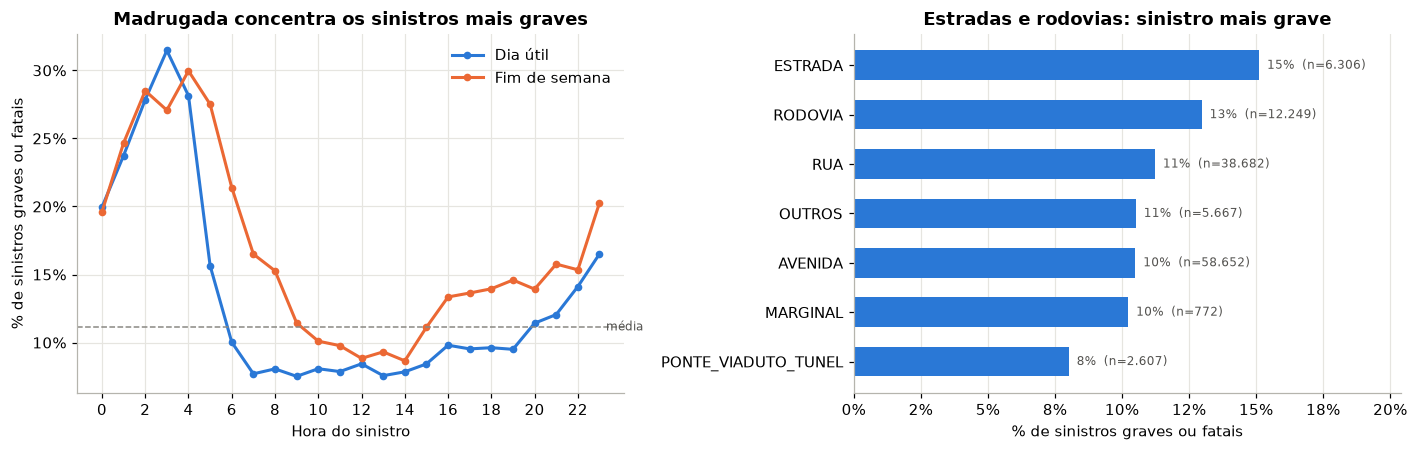

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))

t = df.groupby(["hora", "fim_de_semana"])[ALVO].mean().unstack()
ax = axes[0]
ax.plot(t.index, t[0], color=AZUL, lw=2, marker="o", ms=4, label="Dia útil")
ax.plot(t.index, t[1], color=LARANJA, lw=2, marker="o", ms=4, label="Fim de semana")
ax.axhline(df[ALVO].mean(), color=CINZA, lw=1, ls="--")
ax.text(23.3, df[ALVO].mean(), "média", va="center", fontsize=8, color="#52514e")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax.set_xticks(range(0, 24, 2))
ax.set_xlabel("Hora do sinistro"); ax.set_ylabel("% de sinistros graves ou fatais")
ax.set_title("Madrugada concentra os sinistros mais graves")
ax.legend(loc="upper right")

t2 = df.groupby("tipo_logradouro")[ALVO].agg(["mean", "size"]).sort_values("mean")
ax = axes[1]
ax.barh(t2.index, t2["mean"], color=AZUL, height=0.6)
for y, (m, n) in enumerate(zip(t2["mean"], t2["size"])):
    ax.text(m + 0.003, y, f"{m:.0%}  (n={n:,})".replace(",", "."), va="center", fontsize=8, color="#52514e")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax.set_xlim(0, t2["mean"].max() * 1.35)
ax.set_title("Estradas e rodovias: sinistro mais grave")
ax.set_xlabel("% de sinistros graves ou fatais")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.savefig(FIG / "01_eda_hora_logradouro.png"); plt.show()

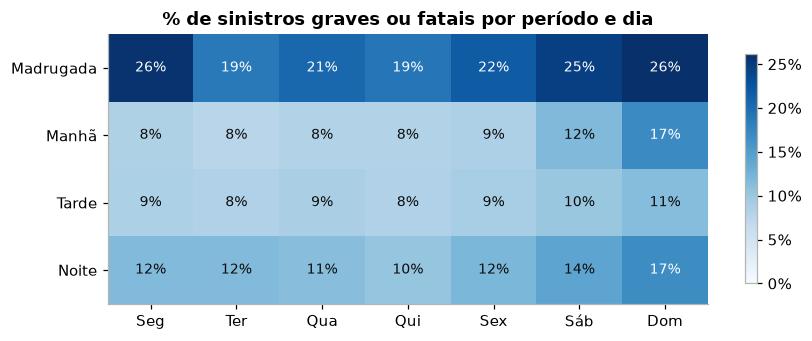

In [8]:
dias = ["Seg", "Ter", "Qua", "Qui", "Sex", "Sáb", "Dom"]
ordem_p = ["MADRUGADA", "MANHA", "TARDE", "NOITE"]
mapa = df.pivot_table(index="periodo", columns="dia_semana", values=ALVO, aggfunc="mean").loc[ordem_p]
fig, ax = plt.subplots(figsize=(8, 3.2))
im = ax.imshow(mapa.values, cmap="Blues", aspect="auto", vmin=0)
ax.set_xticks(range(7), dias); ax.set_yticks(range(4), ["Madrugada", "Manhã", "Tarde", "Noite"])
for i in range(mapa.shape[0]):
    for j in range(mapa.shape[1]):
        v = mapa.values[i, j]
        ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=9,
                color="white" if v > mapa.values.max() * 0.6 else "#0b0b0b")
ax.grid(False)
ax.set_title("% de sinistros graves ou fatais por período e dia")
plt.colorbar(im, ax=ax, format=mtick.PercentFormatter(1, decimals=0), shrink=0.85)
plt.tight_layout(); plt.savefig(FIG / "02_eda_periodo_dia.png"); plt.show()

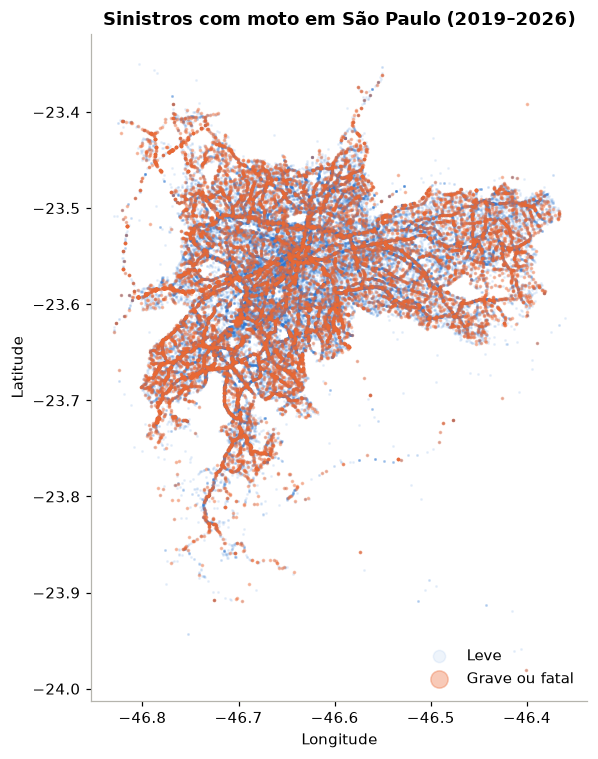

In [9]:
fig, ax = plt.subplots(figsize=(7, 7))
leve, grave = df[df[ALVO] == 0], df[df[ALVO] == 1]
ax.scatter(leve["longitude"], leve["latitude"], s=1, alpha=0.08, color=AZUL, label="Leve", rasterized=True)
ax.scatter(grave["longitude"], grave["latitude"], s=2, alpha=0.35, color=LARANJA, label="Grave ou fatal", rasterized=True)
ax.set_aspect("equal"); ax.grid(False)
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
ax.set_title("Sinistros com moto em São Paulo (2019–2026)")
ax.legend(markerscale=8, loc="lower right")
plt.tight_layout(); plt.savefig(FIG / "03_mapa_sinistros.png"); plt.show()

## 6. Modelo escolhido: XGBoost — justificativa

- **Dado tabular** com mistura de variáveis numéricas (hora, coordenadas, distância) e categóricas (tipo de via,
  período). Modelos de árvore com *gradient boosting* são o estado da arte para esse tipo de dado.
- **Classes desbalanceadas** (~12% graves): o XGBoost tem o parâmetro `scale_pos_weight`, que dá peso maior
  aos exemplos da classe grave sem precisar duplicar ou inventar linhas.
- **Interações não lineares**: "madrugada **e** rodovia **e** fim de semana" é mais perigoso do que a soma das
  partes. Árvores capturam isso sozinhas; uma regressão linear não.
- **Coordenadas**: árvores recortam o mapa em regiões (lat/lng) sem precisar de mapa de bairros.
- **Explicável**: dá para medir a importância de cada variável, o que permite explicar o score ao motoboy.

Por que não os outros da lista: **LSTM** é para sequências temporais (não é o caso, cada sinistro é independente);
**KMeans+PCA** é não supervisionado e não responde "qual a chance de ser grave"; **MLP** exigiria normalização e
dá menos explicabilidade; **Random Forest** seria a alternativa, mas não tem `scale_pos_weight` nativo e costuma
perder do boosting em dado tabular.

## 7. Divisão treino / teste

80% treino e 20% teste, **estratificado** pela classe grave (as duas partes ficam com a mesma proporção).
O teste fica guardado e só é usado **uma vez**, no fim.

In [10]:
X = df[NUM + CAT]
y = df[ALVO]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)

divisao = pd.DataFrame({
    "linhas": [len(X_train), len(X_test)],
    "graves": [int(y_train.sum()), int(y_test.sum())],
    "% graves": [y_train.mean(), y_test.mean()],
}, index=["treino (80%)", "teste (20%)"])
print(divisao.to_string(formatters={"% graves": "{:.2%}".format}))

spw = (y_train == 0).sum() / (y_train == 1).sum()
print(f"\nscale_pos_weight = leves / graves no treino = {spw:.2f}")

              linhas  graves % graves
treino (80%)   99948   11142   11.15%
teste (20%)    24987    2785   11.15%

scale_pos_weight = leves / graves no treino = 7.97


## 8. Treino com diferentes hiperparâmetros + validação cruzada **só no treino**

**3 hiperparâmetros**, **18 combinações** (3 × 3 × 2):

| Hiperparâmetro | Valores | O que controla |
|---|---|---|
| `max_depth` | 3, 5, 7 | profundidade de cada árvore (complexidade) |
| `learning_rate` | 0,03 · 0,1 · 0,3 | tamanho do passo de cada nova árvore |
| `n_estimators` | 100, 300 | número de árvores |

- `GridSearchCV` com **5 dobras estratificadas**, aplicado **apenas em `X_train`**. O conjunto de teste não participa.
- Métricas calculadas em cada dobra: **ROC-AUC**, **recall** e **F1 da classe grave** e **average precision**.
- Critério de escolha (`refit`): **ROC-AUC**. O app usa o resultado para **ordenar** regiões da mais à menos perigosa,
  e o ROC-AUC mede justamente a qualidade dessa ordenação, sem depender de um corte. O recall da classe grave é
  garantido pelo `scale_pos_weight` e é mostrado ao lado.
- `return_train_score=True`: guardamos também a nota de treino de cada combinação para enxergar overfitting.

In [11]:
pre = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), CAT)], remainder="passthrough")
modelo = Pipeline([
    ("pre", pre),
    ("xgb", XGBClassifier(objective="binary:logistic", eval_metric="auc", tree_method="hist",
                          scale_pos_weight=spw, subsample=0.8, colsample_bytree=0.8,
                          random_state=SEED, n_jobs=-1)),
])

grade = {
    "xgb__max_depth": [3, 5, 7],
    "xgb__learning_rate": [0.03, 0.1, 0.3],
    "xgb__n_estimators": [100, 300],
}
metricas = {"roc_auc": "roc_auc", "recall": "recall", "f1": "f1", "avg_precision": "average_precision"}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

busca = GridSearchCV(modelo, grade, scoring=metricas, refit="roc_auc", cv=cv,
                     return_train_score=True, n_jobs=1, verbose=0)
t0 = time.time()
busca.fit(X_train, y_train)
print(f"{len(busca.cv_results_['params'])} combinações × 5 dobras = "
      f"{len(busca.cv_results_['params']) * 5} treinos em {time.time() - t0:.0f} s")
print("Melhor combinação:", {k.replace('xgb__', ''): v for k, v in busca.best_params_.items()})
print(f"ROC-AUC médio na validação cruzada: {busca.best_score_:.4f}")

18 combinações × 5 dobras = 90 treinos em 159 s
Melhor combinação: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 100}
ROC-AUC médio na validação cruzada: 0.6451


In [12]:
r = pd.DataFrame(busca.cv_results_)
tabela = pd.DataFrame({
    "max_depth": r["param_xgb__max_depth"],
    "learning_rate": r["param_xgb__learning_rate"],
    "n_estimators": r["param_xgb__n_estimators"],
    "AUC treino": r["mean_train_roc_auc"],
    "AUC validação": r["mean_test_roc_auc"],
    "± (dp)": r["std_test_roc_auc"],
    "Recall validação": r["mean_test_recall"],
    "F1 validação": r["mean_test_f1"],
    "Gap AUC (treino − val)": r["mean_train_roc_auc"] - r["mean_test_roc_auc"],
    "posição": r["rank_test_roc_auc"],
}).sort_values("posição").reset_index(drop=True)
tabela.to_csv(FIG / "tabela_grid_search.csv", index=False)
tabela.style.format({c: "{:.4f}" for c in tabela.columns if tabela[c].dtype == float}) \
    .background_gradient(subset=["AUC validação"], cmap="Blues") \
    .background_gradient(subset=["Gap AUC (treino − val)"], cmap="Oranges")

,max_depth,learning_rate,n_estimators,AUC treino,AUC validação,± (dp),Recall validação,F1 validação,Gap AUC (treino − val),posição
0,3,0.1000,100,0.6612,0.6451,0.0055,0.5287,0.2649,0.0161,1
1,3,0.0300,300,0.6596,0.6450,0.0053,0.5244,0.2641,0.0146,2
2,5,0.0300,300,0.7051,0.6442,0.0057,0.5023,0.2657,0.0609,3
3,3,0.1000,300,0.6865,0.6438,0.0046,0.5202,0.2651,0.0427,4
4,5,0.0300,100,0.6655,0.6434,0.0052,0.5122,0.2645,0.0222,5
5,5,0.1000,100,0.7076,0.6416,0.0054,0.5024,0.2649,0.0659,6
6,7,0.0300,100,0.7088,0.6412,0.0052,0.4847,0.2648,0.0676,7
7,3,0.3000,100,0.6827,0.6397,0.0055,0.5175,0.2621,0.0430,8
8,3,0.0300,100,0.6457,0.6395,0.0053,0.5145,0.2631,0.0061,9
9,7,0.0300,300,0.7941,0.6353,0.0052,0.4469,0.2629,0.1588,10


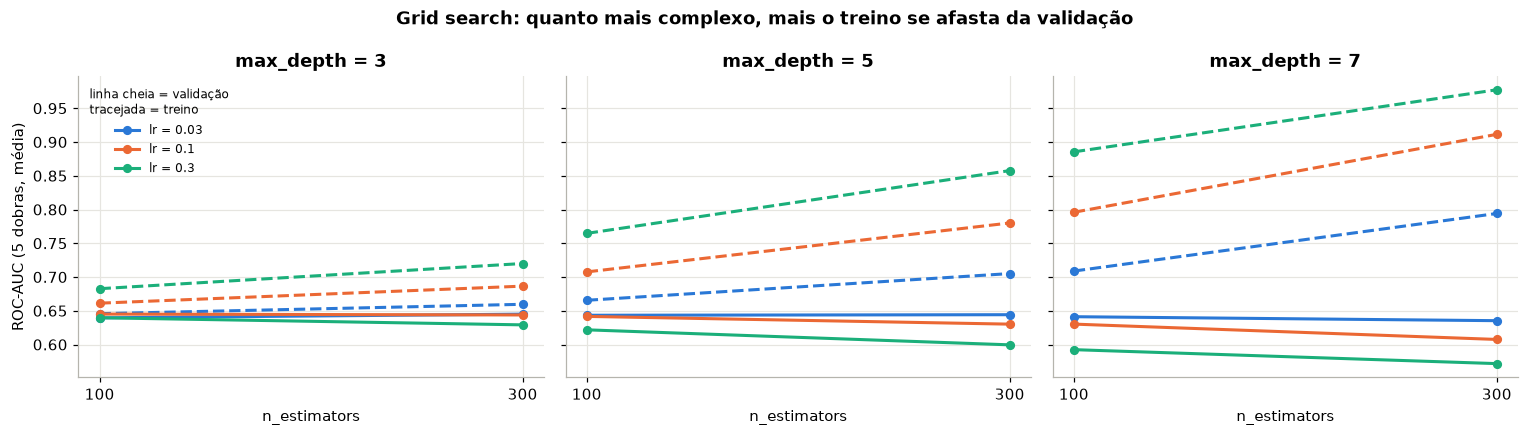

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, prof in zip(axes, [3, 5, 7]):
    for lr, cor in zip([0.03, 0.1, 0.3], [AZUL, LARANJA, VERDE]):
        s = r[(r["param_xgb__max_depth"] == prof) & (r["param_xgb__learning_rate"] == lr)] \
            .sort_values("param_xgb__n_estimators")
        ax.plot(s["param_xgb__n_estimators"], s["mean_train_roc_auc"], color=cor, lw=2, ls="--", marker="o", ms=5)
        ax.plot(s["param_xgb__n_estimators"], s["mean_test_roc_auc"], color=cor, lw=2, marker="o", ms=5,
                label=f"lr = {lr}")
    ax.set_title(f"max_depth = {prof}")
    ax.set_xticks([100, 300]); ax.set_xlabel("n_estimators")
axes[0].set_ylabel("ROC-AUC (5 dobras, média)")
axes[0].legend(title="linha cheia = validação\ntracejada = treino", loc="upper left", fontsize=8, title_fontsize=8)
fig.suptitle("Grid search: quanto mais complexo, mais o treino se afasta da validação", fontweight="bold")
plt.tight_layout(); plt.savefig(FIG / "04_grid_search.png"); plt.show()

### 8.1 Corte de decisão: priorizar o recall

Com o corte padrão de 0,5 o modelo encontra só cerca de metade dos sinistros graves. Para o Guardião, **deixar de
avisar um trecho perigoso é pior do que avisar à toa**, então escolhemos o corte que garante **recall ≥ 70%**.

O corte é escolhido **só com o treino**: geramos previsões *fora da dobra* (`cross_val_predict`, 5 dobras) no
conjunto de treino e pegamos o maior corte que ainda atinge 70% de recall. O teste continua intocado.

In [14]:
from sklearn.base import clone
oof_treino = cross_val_predict(clone(busca.best_estimator_), X_train, y_train, cv=cv, method="predict_proba")[:, 1]
fpr_o, tpr_o, thr_o = roc_curve(y_train, oof_treino)
RECALL_ALVO = 0.70
CORTE = float(thr_o[np.argmax(tpr_o >= RECALL_ALVO)])
print(f"Corte escolhido no treino (validação cruzada): {CORTE:.3f}")
print(f"Recall fora da dobra com esse corte: {recall_score(y_train, oof_treino >= CORTE):.3f} | "
      f"com corte 0,5: {recall_score(y_train, oof_treino >= 0.5):.3f}")

Corte escolhido no treino (validação cruzada): 0.436
Recall fora da dobra com esse corte: 0.700 | com corte 0,5: 0.529


## 9. Resultados: treino × teste lado a lado

O melhor pipeline (já re-treinado pelo `GridSearchCV` em todo o conjunto de treino) é avaliado uma única vez
no conjunto de teste, com o **corte ajustado** (seção 8.1). A tabela mostra também o corte padrão de 0,5 para comparação.

In [15]:
melhor = busca.best_estimator_

def avaliar(Xp, yp, corte=None):
    corte = CORTE if corte is None else corte
    proba = melhor.predict_proba(Xp)[:, 1]
    pred = (proba >= corte).astype(int)
    return {
        "ROC-AUC": roc_auc_score(yp, proba),
        "Average precision (PR-AUC)": average_precision_score(yp, proba),
        "Recall (grave)": recall_score(yp, pred),
        "Precisão (grave)": precision_score(yp, pred),
        "F1 (grave)": f1_score(yp, pred),
        "Acurácia balanceada": balanced_accuracy_score(yp, pred),
        "Acurácia (só referência)": accuracy_score(yp, pred),
    }, proba

m_treino, p_treino = avaliar(X_train, y_train)
m_teste, p_teste = avaliar(X_test, y_test)
m_treino_05, _ = avaliar(X_train, y_train, 0.5)
m_teste_05, _ = avaliar(X_test, y_test, 0.5)
res = pd.DataFrame({"Treino": m_treino, "Teste": m_teste})
res["Diferença"] = res["Treino"] - res["Teste"]
res[f"Treino (corte 0,5)"] = pd.Series(m_treino_05)
res[f"Teste (corte 0,5)"] = pd.Series(m_teste_05)
res.to_csv(FIG / "tabela_treino_teste.csv")
print(f"Corte ajustado = {CORTE:.3f} (colunas Treino/Teste). ROC-AUC e PR-AUC não dependem do corte.")
res.style.format("{:.4f}")

Corte ajustado = 0.436 (colunas Treino/Teste). ROC-AUC e PR-AUC não dependem do corte.


,Treino,Teste,Diferença,"Treino (corte 0,5)","Teste (corte 0,5)"
ROC-AUC,0.6580,0.6408,0.0172,0.6580,0.6408
Average precision (PR-AUC),0.2200,0.1999,0.0201,0.2200,0.1999
Recall (grave),0.7178,0.7052,0.0126,0.5454,0.5260
Precisão (grave),0.1478,0.1442,0.0036,0.1810,0.1730
F1 (grave),0.2451,0.2394,0.0057,0.2719,0.2604
Acurácia balanceada,0.5993,0.5901,0.0092,0.6179,0.6053
Acurácia (só referência),0.5072,0.5006,0.0066,0.6743,0.6669


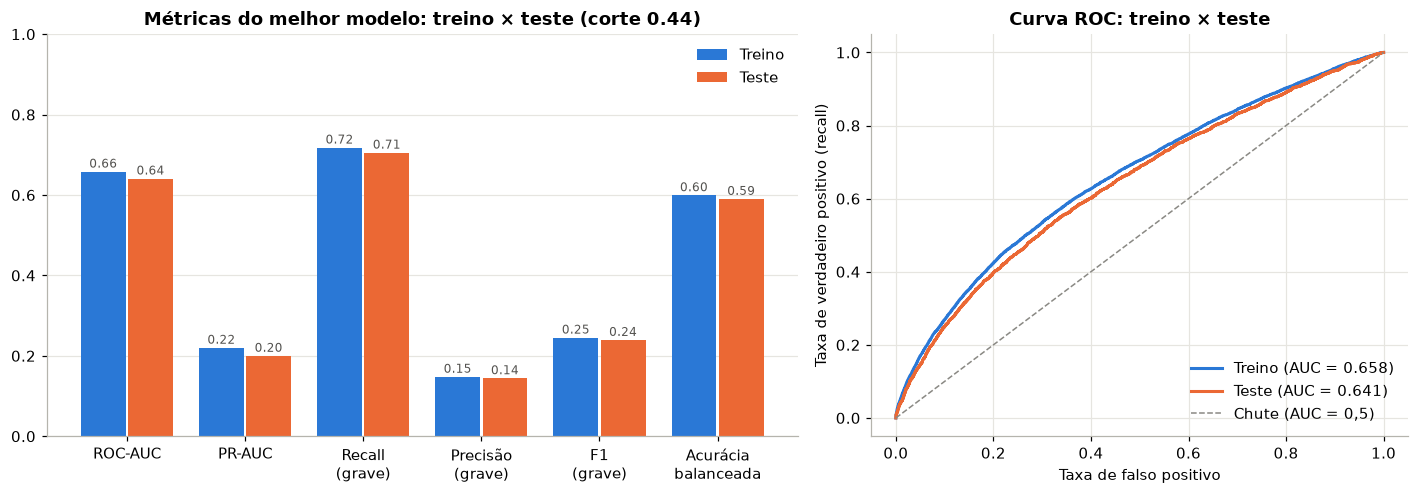

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1.4, 1]})
ax = axes[0]
nomes = ["ROC-AUC", "Average precision (PR-AUC)", "Recall (grave)", "Precisão (grave)", "F1 (grave)", "Acurácia balanceada"]
rot = ["ROC-AUC", "PR-AUC", "Recall\n(grave)", "Precisão\n(grave)", "F1\n(grave)", "Acurácia\nbalanceada"]
xx = np.arange(len(nomes)); w = 0.38
b1 = ax.bar(xx - w/2 - 0.01, res.loc[nomes, "Treino"], w, color=AZUL, label="Treino")
b2 = ax.bar(xx + w/2 + 0.01, res.loc[nomes, "Teste"], w, color=LARANJA, label="Teste")
for barras in (b1, b2):
    for b in barras:
        ax.text(b.get_x() + b.get_width()/2, b.get_height() + 0.01, f"{b.get_height():.2f}",
                ha="center", fontsize=8, color="#52514e")
ax.set_xticks(xx, rot); ax.set_ylim(0, 1); ax.grid(axis="x", visible=False)
ax.set_title(f"Métricas do melhor modelo: treino × teste (corte {CORTE:.2f})"); ax.legend(loc="upper right")

ax = axes[1]
for yp, pp, cor, nome in [(y_train, p_treino, AZUL, "Treino"), (y_test, p_teste, LARANJA, "Teste")]:
    fpr, tpr, _ = roc_curve(yp, pp)
    ax.plot(fpr, tpr, color=cor, lw=2, label=f"{nome} (AUC = {roc_auc_score(yp, pp):.3f})")
ax.plot([0, 1], [0, 1], color=CINZA, lw=1, ls="--", label="Chute (AUC = 0,5)")
ax.set_xlabel("Taxa de falso positivo"); ax.set_ylabel("Taxa de verdadeiro positivo (recall)")
ax.set_title("Curva ROC: treino × teste"); ax.legend(loc="lower right")
plt.tight_layout(); plt.savefig(FIG / "05_treino_vs_teste.png"); plt.show()

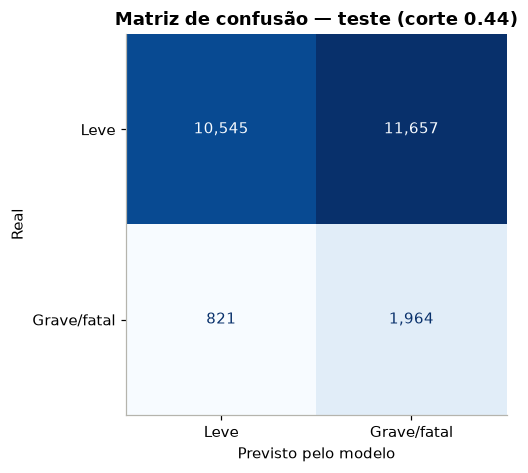

Graves identificados: 1964 de 2785 (70.5%) | graves perdidos: 821
Alarmes a mais (leve marcado como grave): 11657 de 22202 (52.5%)


In [17]:
fig, ax = plt.subplots(figsize=(5.2, 4.4))
cm = confusion_matrix(y_test, (p_teste >= CORTE).astype(int))
ConfusionMatrixDisplay(cm, display_labels=["Leve", "Grave/fatal"]).plot(ax=ax, cmap="Blues", colorbar=False, values_format=",d")
ax.grid(False); ax.set_xlabel("Previsto pelo modelo"); ax.set_ylabel("Real")
ax.set_title(f"Matriz de confusão — teste (corte {CORTE:.2f})")
plt.tight_layout(); plt.savefig(FIG / "06_matriz_confusao.png"); plt.show()
vn, fp, fn, vp = cm.ravel()
print(f"Graves identificados: {vp} de {vp + fn} ({vp/(vp+fn):.1%}) | graves perdidos: {fn}")
print(f"Alarmes a mais (leve marcado como grave): {fp} de {fp + vn} ({fp/(fp+vn):.1%})")

### 9.1 Importância das variáveis

Usamos a **importância por permutação** no conjunto de teste: embaralhamos uma variável de cada vez e medimos
quanto o ROC-AUC cai. Ela mede cada variável original (e não cada coluna do one-hot) e é mais honesta do que a
importância interna das árvores.

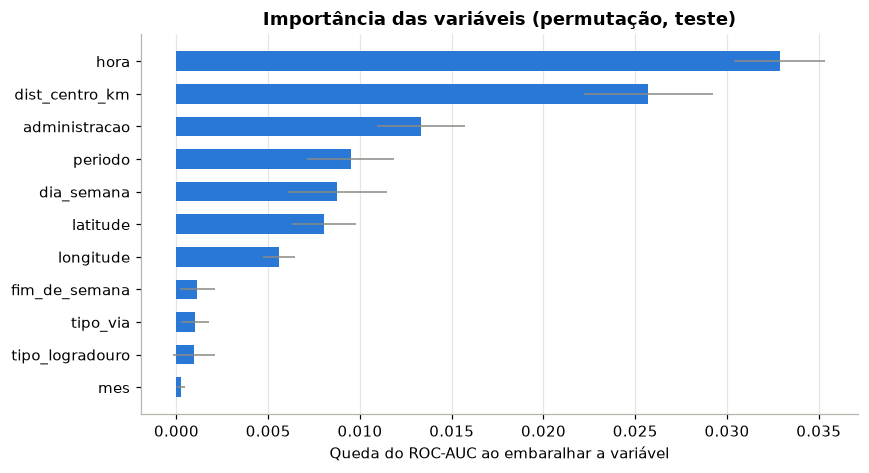

,variavel,queda_auc,dp
0,hora,0.0329,0.0025
6,dist_centro_km,0.0257,0.0035
10,administracao,0.0133,0.0024
7,periodo,0.0095,0.0024
1,dia_semana,0.0088,0.0027
4,latitude,0.0080,0.0018
5,longitude,0.0056,0.0009
2,fim_de_semana,0.0011,0.0010
8,tipo_via,0.0010,0.0008
9,tipo_logradouro,0.0010,0.0011


In [18]:
amostra = X_test.sample(n=min(8000, len(X_test)), random_state=SEED)
perm = permutation_importance(melhor, amostra, y_test.loc[amostra.index], scoring="roc_auc",
                              n_repeats=5, random_state=SEED, n_jobs=1)
imp = pd.DataFrame({"variavel": X_test.columns, "queda_auc": perm.importances_mean, "dp": perm.importances_std}) \
    .sort_values("queda_auc")
fig, ax = plt.subplots(figsize=(8, 4.4))
ax.barh(imp["variavel"], imp["queda_auc"], xerr=imp["dp"], color=AZUL, height=0.6,
        error_kw={"ecolor": CINZA, "lw": 1})
ax.set_xlabel("Queda do ROC-AUC ao embaralhar a variável")
ax.set_title("Importância das variáveis (permutação, teste)")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.savefig(FIG / "07_importancia_variaveis.png"); plt.show()
imp.sort_values("queda_auc", ascending=False).round(4)

### 9.2 Overfitting

O que olhar: se o desempenho no treino estiver **muito acima** do teste, o modelo decorou o treino.

In [19]:
gap = res.loc["ROC-AUC", "Diferença"]
print(f"ROC-AUC treino = {res.loc['ROC-AUC','Treino']:.3f} | teste = {res.loc['ROC-AUC','Teste']:.3f} | diferença = {gap:.3f}")
print(f"ROC-AUC validação cruzada (média 5 dobras) = {busca.best_score_:.3f}")
pior = tabela.sort_values("Gap AUC (treino − val)", ascending=False).iloc[0]
print(f"Combinação mais 'decorada' da grade: depth={pior['max_depth']}, lr={pior['learning_rate']}, "
      f"n={pior['n_estimators']} -> AUC treino {pior['AUC treino']:.3f} vs validação {pior['AUC validação']:.3f}")

ROC-AUC treino = 0.658 | teste = 0.641 | diferença = 0.017
ROC-AUC validação cruzada (média 5 dobras) = 0.645
Combinação mais 'decorada' da grade: depth=7.0, lr=0.3, n=300.0 -> AUC treino 0.977 vs validação 0.572


## 10. Do modelo ao app: `zonas_risco.csv`

A cidade é dividida em uma **grade de ~2 km × 2 km** (latitude e longitude arredondadas a cada 0,02°). Para cada
célula da grade e cada **faixa horária** (madrugada, manhã, tarde, noite):

1. Pegamos a probabilidade **fora da amostra** que o modelo dá a cada sinistro real daquela célula/faixa
   (`cross_val_predict` com 5 dobras e os melhores hiperparâmetros — nenhum sinistro é avaliado por um modelo que o viu no treino).
2. `prob_modelo` = média dessas probabilidades.
3. `score` (0 a 1) = posição percentual da zona entre todas as zonas: 0,81 quer dizer "mais arriscada que 81% das zonas".
   Usamos a posição porque o `scale_pos_weight` desloca as probabilidades para cima; a **ordem** é o que o modelo acerta.
4. `nivel`: **ALTO** se score ≥ 0,80 · **MEDIO** se 0,40 ≤ score < 0,80 · **BAIXO** abaixo disso.
5. `risco_relativo` = `prob_modelo` ÷ média da cidade (quantas vezes acima da média).
6. Só entram zonas×faixa com **pelo menos 30 sinistros** (abaixo disso a estimativa é instável).

O nome de cada zona é o logradouro com mais sinistros dentro da célula.

In [20]:
oof_modelo = Pipeline([("pre", pre), ("xgb", XGBClassifier(
    objective="binary:logistic", tree_method="hist", scale_pos_weight=spw, subsample=0.8,
    colsample_bytree=0.8, random_state=SEED, n_jobs=-1,
    **{k.replace("xgb__", ""): v for k, v in busca.best_params_.items()}))])
spw_total = (y == 0).sum() / (y == 1).sum()
oof_modelo.set_params(xgb__scale_pos_weight=spw_total)
df["prob_modelo"] = cross_val_predict(oof_modelo, X, y, cv=cv, method="predict_proba")[:, 1]

PASSO = 0.02
df["cel_lat"] = (np.floor(df["latitude"] / PASSO) * PASSO + PASSO / 2).round(3)
df["cel_lng"] = (np.floor(df["longitude"] / PASSO) * PASSO + PASSO / 2).round(3)

FAIXAS = {"MADRUGADA": (0, 5), "MANHA": (6, 11), "TARDE": (12, 17), "NOITE": (18, 23)}

def nome_zona(s):
    top = s.value_counts().index[0]
    top = (top.replace("AVENIDA ", "Av. ").replace("RUA ", "R. ").replace("ESTRADA ", "Estr. ").title()
              .replace("Av. ", "Av. ").replace(" Da ", " da ").replace(" De ", " de ").replace(" Do ", " do ")
              .replace(" Dos ", " dos ").replace(" Das ", " das "))
    top = re.sub(r"^(Sp|Br) (\d+)", lambda m: f"{m.group(1).upper()}-{m.group(2)}", top)
    return f"{top} e entorno"

nomes = df.assign(logradouro=df["logradouro"].fillna("REGIAO SEM NOME")) \
    .groupby(["cel_lat", "cel_lng"])["logradouro"].agg(nome_zona)
zonas = (df.groupby(["cel_lat", "cel_lng", "periodo"])
           .agg(n_sinistros=(ALVO, "size"), taxa_grave_observada=(ALVO, "mean"), prob_modelo=("prob_modelo", "mean"))
           .reset_index())
zonas = zonas[zonas["n_sinistros"] >= 30].copy()
zonas["nome"] = [nomes.loc[(a, b)] for a, b in zip(zonas["cel_lat"], zonas["cel_lng"])]
zonas["score"] = zonas["prob_modelo"].rank(pct=True).round(2)
zonas["nivel"] = np.select([zonas["score"] >= 0.80, zonas["score"] >= 0.40], ["ALTO", "MEDIO"], "BAIXO")
zonas["risco_relativo"] = (zonas["prob_modelo"] / df["prob_modelo"].mean()).round(2)
zonas["hora_inicio"] = zonas["periodo"].map(lambda p: FAIXAS[p][0])
zonas["hora_fim"] = zonas["periodo"].map(lambda p: FAIXAS[p][1])

celulas = zonas[["cel_lat", "cel_lng"]].drop_duplicates().sort_values(["cel_lat", "cel_lng"]).reset_index(drop=True)
celulas["zona_id"] = np.arange(1, len(celulas) + 1)
zonas = zonas.merge(celulas, on=["cel_lat", "cel_lng"])

saida = zonas.rename(columns={"cel_lat": "latitude", "cel_lng": "longitude", "periodo": "faixa_horaria"})[
    ["zona_id", "nome", "latitude", "longitude", "faixa_horaria", "hora_inicio", "hora_fim",
     "score", "nivel", "risco_relativo", "prob_modelo", "taxa_grave_observada", "n_sinistros"]]
saida = saida.assign(prob_modelo=saida["prob_modelo"].round(4),
                     taxa_grave_observada=saida["taxa_grave_observada"].round(4)) \
             .sort_values(["zona_id", "hora_inicio"]).reset_index(drop=True)
saida.to_csv("zonas_risco.csv", index=False, encoding="utf-8")
print(f"zonas_risco.csv: {len(saida)} linhas | {saida['zona_id'].nunique()} zonas de ~2 km | "
      f"{saida['n_sinistros'].sum():,} sinistros cobertos".replace(",", "."))
print(saida["nivel"].value_counts().to_string())
print("\nCorrelação (Spearman) entre score do modelo e taxa observada nas zonas:",
      round(saida["prob_modelo"].corr(saida["taxa_grave_observada"], method="spearman"), 3))
saida.sort_values("score", ascending=False).head(10)

zonas_risco.csv: 794 linhas | 222 zonas de ~2 km | 120.491 sinistros cobertos
nivel
MEDIO    318
BAIXO    313
ALTO     163

Correlação (Spearman) entre score do modelo e taxa observada nas zonas: 0.811


,zona_id,nome,latitude,longitude,faixa_horaria,hora_inicio,hora_fim,score,nivel,risco_relativo,prob_modelo,taxa_grave_observada,n_sinistros
27,10,Av. Dona Belmira Marin e entorno,-23.75,-46.67,MADRUGADA,0,5,1.00,ALTO,1.65,0.7803,0.4186,43
285,79,SP-270 e entorno,-23.59,-46.77,MADRUGADA,0,5,1.00,ALTO,1.65,0.7795,0.4237,59
14,6,Av. Antonio Carlos Benjamim dos Santos e entorno,-23.77,-46.69,MADRUGADA,0,5,1.00,ALTO,1.66,0.7843,0.4865,37
281,78,SP-270 e entorno,-23.59,-46.79,MADRUGADA,0,5,1.00,ALTO,1.66,0.7844,0.3421,38
42,14,Estr. do M'Boi Mirim e entorno,-23.71,-46.79,MADRUGADA,0,5,0.99,ALTO,1.63,0.7715,0.3611,36
351,97,Av. dos Metalurgicos e entorno,-23.59,-46.41,MADRUGADA,0,5,0.99,ALTO,1.63,0.7701,0.2333,30
289,80,SP-270 e entorno,-23.59,-46.75,MADRUGADA,0,5,0.99,ALTO,1.63,0.7690,0.2632,38
10,5,Av. Paulo Guilguer Reimberg e entorno,-23.77,-46.71,MADRUGADA,0,5,0.99,ALTO,1.61,0.7615,0.2647,34
62,20,R. Feitico da Vila e entorno,-23.69,-46.79,MADRUGADA,0,5,0.99,ALTO,1.62,0.7678,0.2791,43
31,11,Estr. do M'Boi Mirim e entorno,-23.73,-46.79,MADRUGADA,0,5,0.99,ALTO,1.62,0.7675,0.3548,31


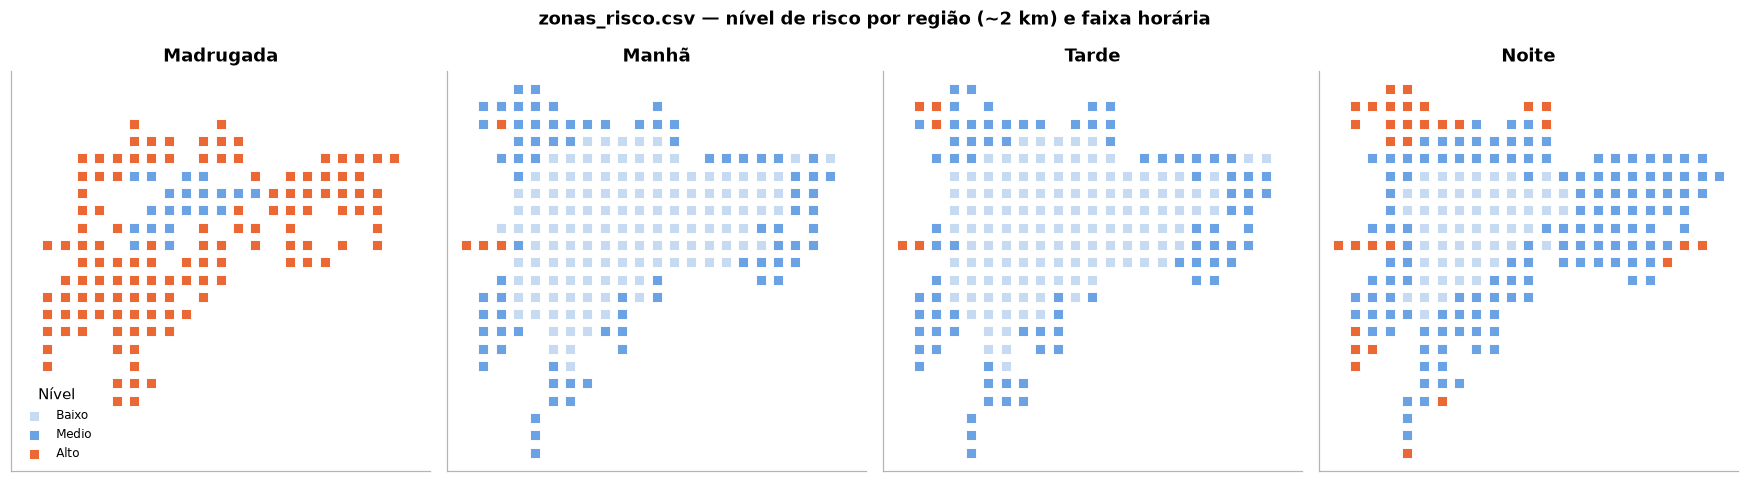

In [21]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4.6), sharex=True, sharey=True)
cores_nivel = {"BAIXO": "#c6dbf1", "MEDIO": "#6aa2e4", "ALTO": LARANJA}
for ax, p in zip(axes, ["MADRUGADA", "MANHA", "TARDE", "NOITE"]):
    s = saida[saida["faixa_horaria"] == p]
    for nv in ["BAIXO", "MEDIO", "ALTO"]:
        q = s[s["nivel"] == nv]
        ax.scatter(q["longitude"], q["latitude"], s=38, marker="s", color=cores_nivel[nv],
                   edgecolor="white", linewidth=0.6, label=nv.title())
    ax.set_title(p.title().replace("Manha", "Manhã")); ax.set_aspect("equal"); ax.grid(False)
    ax.set_xticks([]); ax.set_yticks([])
axes[0].legend(title="Nível", loc="lower left", fontsize=8)
fig.suptitle("zonas_risco.csv — nível de risco por região (~2 km) e faixa horária", fontweight="bold")
plt.tight_layout(); plt.savefig(FIG / "08_mapa_zonas_risco.png"); plt.show()

## 11. Leitura para o cidadão

Abaixo, as comparações calculadas direto do dado real (não do modelo), em linguagem de motoboy.

In [22]:
base = df[ALVO].mean()
def taxa(mask):
    return df.loc[mask, ALVO].mean(), int(mask.sum())

frases = {}
t_mad_fds, n1 = taxa((df["periodo"] == "MADRUGADA") & (df["fim_de_semana"] == 1))
t_tarde_util, n2 = taxa((df["periodo"] == "TARDE") & (df["fim_de_semana"] == 0))
frases["madrugada_fds_vs_tarde_util"] = t_mad_fds / t_tarde_util
print(f"Madrugada de fim de semana: {t_mad_fds:.1%} graves (n={n1}) | tarde de dia útil: {t_tarde_util:.1%} (n={n2})")
print(f"  -> um acidente de moto na madrugada de sábado/domingo tem {t_mad_fds/t_tarde_util:.1f}x mais chance de ser grave.")

t_rod, n3 = taxa(df["tipo_logradouro"].isin(["RODOVIA", "ESTRADA"]))
t_rua, n4 = taxa(df["tipo_logradouro"].isin(["RUA", "AVENIDA"]))
frases["estrada_rodovia_vs_rua_avenida"] = t_rod / t_rua
print(f"\nEstrada/rodovia: {t_rod:.1%} (n={n3}) | rua/avenida: {t_rua:.1%} (n={n4}) -> {t_rod/t_rua:.2f}x")

t_long, n5 = taxa(df["dist_centro_km"] >= 15)
t_cen, n6 = taxa(df["dist_centro_km"] < 5)
frases["periferia_vs_centro"] = t_long / t_cen
print(f"A 15 km ou mais do centro: {t_long:.1%} (n={n5}) | até 5 km do centro: {t_cen:.1%} (n={n6}) -> {t_long/t_cen:.1f}x")

top = saida.sort_values("risco_relativo", ascending=False).iloc[0]
frases["zona_top"] = {k: (v.item() if hasattr(v, "item") else v) for k, v in top.to_dict().items()}
print(f"\nZona mais arriscada: {top['nome']} na {top['faixa_horaria'].lower()} — "
      f"{top['taxa_grave_observada']:.0%} dos sinistros foram graves (n={top['n_sinistros']}), "
      f"{top['taxa_grave_observada']/base:.1f}x a média da cidade ({base:.1%}).")

top5 = (saida[saida["faixa_horaria"] == "MADRUGADA"].sort_values("score", ascending=False)
        .head(5)[["nome", "score", "nivel", "taxa_grave_observada", "n_sinistros"]])
print("\nTop 5 zonas na madrugada:")
print(top5.to_string(index=False))

resumo = {
    "n_linhas_modelo": int(len(df)), "periodo": [f"{df['data'].min():%d/%m/%Y}", f"{df['data'].max():%d/%m/%Y}"],
    "taxa_grave": float(base), "spw": float(spw), "melhores_params": busca.best_params_,
    "auc_cv": float(busca.best_score_), "corte": CORTE, "treino": m_treino, "teste": m_teste,
    "treino_corte_05": m_treino_05, "teste_corte_05": m_teste_05,
    "funil": funil, "frases": frases, "n_zonas": int(saida["zona_id"].nunique()), "n_linhas_zonas": int(len(saida)),
    "importancia": imp.sort_values("queda_auc", ascending=False)[["variavel", "queda_auc"]].values.tolist(),
}
with open(FIG / "resumo_metricas.json", "w", encoding="utf-8") as f:
    json.dump(resumo, f, ensure_ascii=False, indent=2, default=float)

Madrugada de fim de semana: 25.4% graves (n=4337) | tarde de dia útil: 8.6% (n=32055)
  -> um acidente de moto na madrugada de sábado/domingo tem 2.9x mais chance de ser grave.

Estrada/rodovia: 13.7% (n=18555) | rua/avenida: 10.8% (n=97334) -> 1.27x
A 15 km ou mais do centro: 14.4% (n=36348) | até 5 km do centro: 7.8% (n=17648) -> 1.9x

Zona mais arriscada: SP-270 e entorno na madrugada — 34% dos sinistros foram graves (n=38), 3.1x a média da cidade (11.1%).

Top 5 zonas na madrugada:
                                            nome  score nivel  taxa_grave_observada  n_sinistros
Av. Antonio Carlos Benjamim dos Santos e entorno   1.00  ALTO                0.4865           37
                Av. Dona Belmira Marin e entorno   1.00  ALTO                0.4186           43
                                SP-270 e entorno   1.00  ALTO                0.3421           38
                                SP-270 e entorno   1.00  ALTO                0.4237           59
                  Estr. 

## 12. Conclusão e limites

### O que o modelo entrega

| | Treino | Validação cruzada (5 dobras, só treino) | Teste |
|---|---:|---:|---:|
| ROC-AUC | 0,658 | 0,645 | **0,641** |
| Recall da classe grave (corte 0,44) | 0,718 | 0,70 (alvo usado para escolher o corte) | **0,705** |
| F1 da classe grave (corte 0,44) | 0,245 | — | **0,239** |

- **Sem overfitting relevante:** treino e teste ficam a menos de 0,02 de ROC-AUC. A grade mostra o contrário
  acontecendo nas combinações mais complexas: com `max_depth=7`, `learning_rate=0,3` e 300 árvores o treino chega a
  0,977 e a validação cai para 0,572, um modelo que **decorou** o treino. A validação cruzada só no treino pegou isso
  e escolheu a combinação mais simples (`max_depth=3`, `learning_rate=0,1`, `n_estimators=100`).
- **Recall de 70,5% no teste:** de cada 10 sinistros graves, o modelo marca 7 como perigosos. O preço é a
  precisão baixa (14%): muitos alarmes para sinistros que acabaram leves. Para o Guardião isso é aceitável, porque o
  aviso é de *atenção redobrada*, não um bloqueio da corrida.
- **ROC-AUC de 0,64 é um sinal moderado**, e é o esperado: só usamos onde e quando. Velocidade, capacete e tipo
  de colisão também pesam na gravidade, mas não estão disponíveis antes do acidente.
- **O que mais pesa:** hora do dia, distância até o centro, quem administra a via (rodovia × prefeitura), período e
  dia da semana.

### Em linguagem de motoboy

- **Na madrugada de sábado e domingo, um acidente de moto tem 2,9 vezes mais chance de ser grave ou fatal** do que
  à tarde num dia útil (25,4% contra 8,6%).
- **Longe do centro o tombo é pior:** a 15 km ou mais da Sé, 14,4% dos acidentes com moto são graves; a menos de 5 km,
  7,8% (**1,9 vez**). Na periferia as vias são mais rápidas e o socorro chega mais tarde.
- **Estradas e rodovias** (SP-270, Estrada do M'Boi Mirim etc.) têm acidentes **1,3 vez** mais graves do que ruas e avenidas.
- **Exemplo do app:** na região da SP-270 (Raposo Tavares), de madrugada, 34% dos acidentes com moto foram graves,
  **3,1 vezes** a média da cidade (11,1%). O Guardião mostra essa zona como **ALTO**.

### Limites (honestidade)

- O modelo mede **a gravidade de acidentes que aconteceram**. Ele **não prevê que um acidente vai acontecer**: para
  isso seria preciso saber quantas motos passam em cada lugar e hora (dado de exposição), que não é público.
- Sinistros sem gravidade informada (3% do recorte) e zonas com menos de 30 sinistros ficaram de fora.
- O `scale_pos_weight` desloca as probabilidades para cima. Por isso o app usa o `score` como **posição** (ranking)
  da zona, e não como "probabilidade de morrer".
- **Próximos passos:** chuva por hora do INMET, fluxo de veículos da CET e recalibrar as probabilidades.